# AgriPredict — Exploration des données (EDA)

**Question** : peut-on prédire le rendement (t/ha) du cacao, du maïs et du manioc au Cameroun
à partir du climat (température, pluviométrie) et des intrants agricoles (engrais, pesticides) ?

**Données** : dataset FAOSTAT fusionné, 1990-2024, une ligne = culture/année (105 lignes, 3 cultures × 35 ans).

**Méthode** : lecture du dataset nettoyé (`data/processed/dataset.csv`), puis 3 visualisations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/dataset.csv")
df.head()

,year,crop,yield_t_ha,temp_anomaly,rainfall,fertilizer,pesticides,quality_flag
0,1990,"Cacao, fèves",0.3194,0.586,1328.60,21800.0,2227.0,E
1,1991,"Cacao, fèves",0.3000,0.594,967.25,18100.0,1504.0,E
2,1992,"Cacao, fèves",0.2878,-0.237,1573.15,20900.0,1844.0,E
3,1993,"Cacao, fèves",0.3070,0.179,1777.55,22304.0,1245.0,E
4,1994,"Cacao, fèves",0.3057,0.242,1664.40,30000.0,647.0,E


## 1. Rendement par culture dans le temps

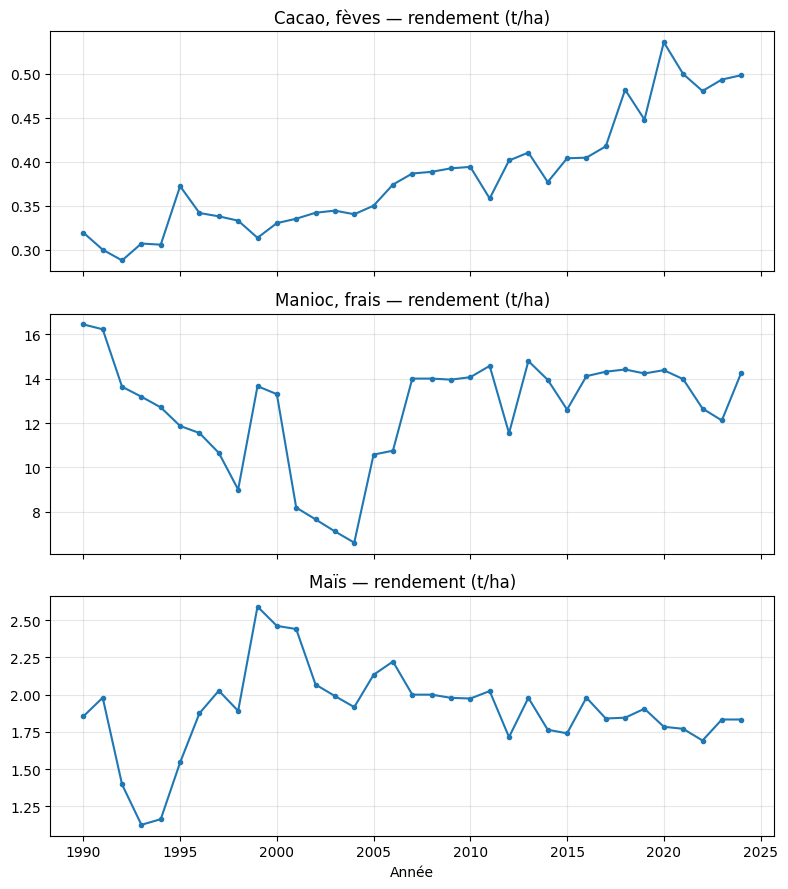

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
for ax, crop in zip(axes, sorted(df["crop"].unique())):
    sub = df[df["crop"] == crop]
    ax.plot(sub["year"], sub["yield_t_ha"], marker="o", markersize=3)
    ax.set_title(f"{crop} — rendement (t/ha)")
    ax.grid(alpha=0.3)
plt.xlabel("Année")
plt.tight_layout()
plt.savefig("../reports/figures/rendement_temps.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Corrélations (toutes cultures confondues)

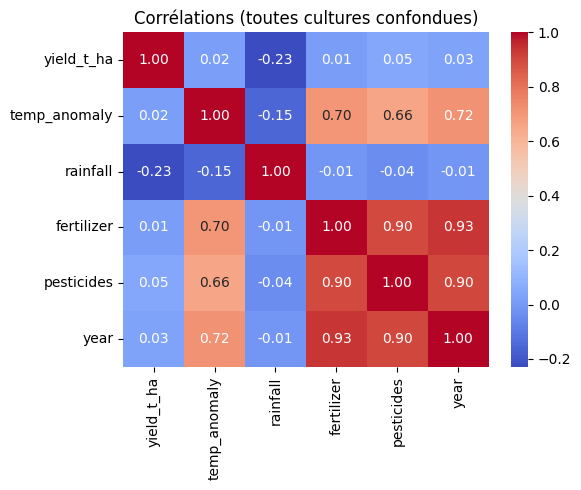

In [3]:
num_cols = ["yield_t_ha", "temp_anomaly", "rainfall", "fertilizer", "pesticides", "year"]
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Corrélations (toutes cultures confondues)")
plt.tight_layout()
plt.savefig("../reports/figures/correlations.png", dpi=150, bbox_inches="tight")
plt.show()

**Attention** : cette heatmap mélange les 3 cultures, dont les échelles de rendement sont très
différentes (0,3 t/ha pour le cacao contre 12 t/ha pour le manioc). Les corrélations par culture,
calculées ci-dessous, sont plus honnêtes.

In [4]:
for crop in sorted(df["crop"].unique()):
    sub = df[df["crop"] == crop]
    corr = sub[num_cols].corr()["yield_t_ha"].drop("yield_t_ha").sort_values(key=abs, ascending=False)
    print(f"\n{crop}:")
    print(corr)


Cacao, fèves:
pesticides      0.919187
year            0.913217
fertilizer      0.889043
temp_anomaly    0.682953
rainfall       -0.205472
Name: yield_t_ha, dtype: float64

Manioc, frais:
pesticides      0.330131
year            0.204521
rainfall       -0.195925
temp_anomaly    0.077782
fertilizer      0.065814
Name: yield_t_ha, dtype: float64

Maïs:
temp_anomaly    0.177285
pesticides     -0.163863
rainfall       -0.105718
fertilizer      0.085388
year            0.050759
Name: yield_t_ha, dtype: float64


## 3. Intrants agricoles dans le temps

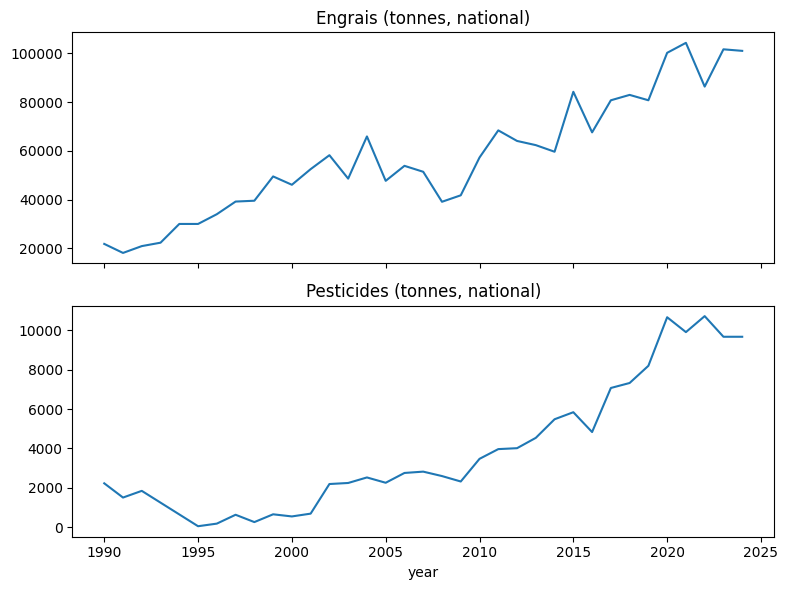

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
df.groupby("year")["fertilizer"].mean().plot(ax=axes[0], title="Engrais (tonnes, national)")
df.groupby("year")["pesticides"].mean().plot(ax=axes[1], title="Pesticides (tonnes, national)")
plt.tight_layout()
plt.savefig("../reports/figures/intrants.png", dpi=150, bbox_inches="tight")
plt.show()

## Interprétation

- **Tendance du rendement** : le cacao affiche une hausse assez régulière depuis les années 2000 ;
  le manioc a un creux marqué entre 2001 et 2004 puis se stabilise ; le maïs oscille sans tendance nette.
- **Variable la plus corrélée** : pour le cacao, `pesticides`, `year` et `fertilizer` sont fortement
  corrélés au rendement (>0,88) — mais cette corrélation reflète surtout une tendance commune dans le
  temps, pas forcément un lien causal. Pour le manioc et le maïs, aucune variable climatique ou
  d'intrant n'est fortement corrélée au rendement.
- **Anomalies visibles** : le creux du manioc en 2001-2004 et le pic du maïs en 1999 ne
  s'expliquent pas clairement par le climat ou les intrants disponibles ici — d'autres facteurs
  (variétés, maladies, politique agricole) sont probablement en jeu.

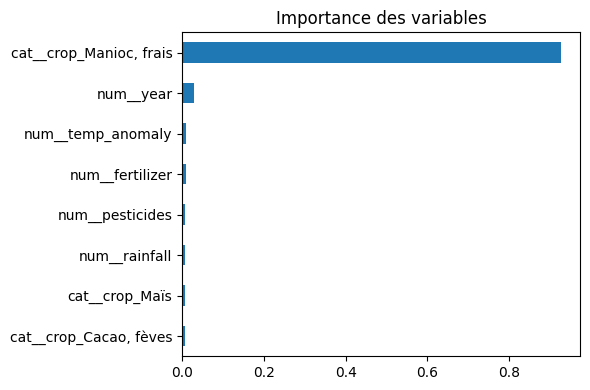

cat__crop_Manioc, frais    0.926894
num__year                  0.028462
num__temp_anomaly          0.010364
num__fertilizer            0.008637
num__pesticides            0.007065
num__rainfall              0.006483
cat__crop_Maïs             0.006153
cat__crop_Cacao, fèves     0.005942
dtype: float64


In [6]:
import joblib
import numpy as np

pipe = joblib.load("../models/model.joblib")
if hasattr(pipe.named_steps["model"], "feature_importances_"):
    names = pipe.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).sort_values()
    imp.plot.barh(figsize=(6, 4), title="Importance des variables")
    plt.tight_layout()
    plt.savefig("../reports/figures/importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(imp.sort_values(ascending=False))

## Prédiction vs réel sur la période de test (5 dernières années)

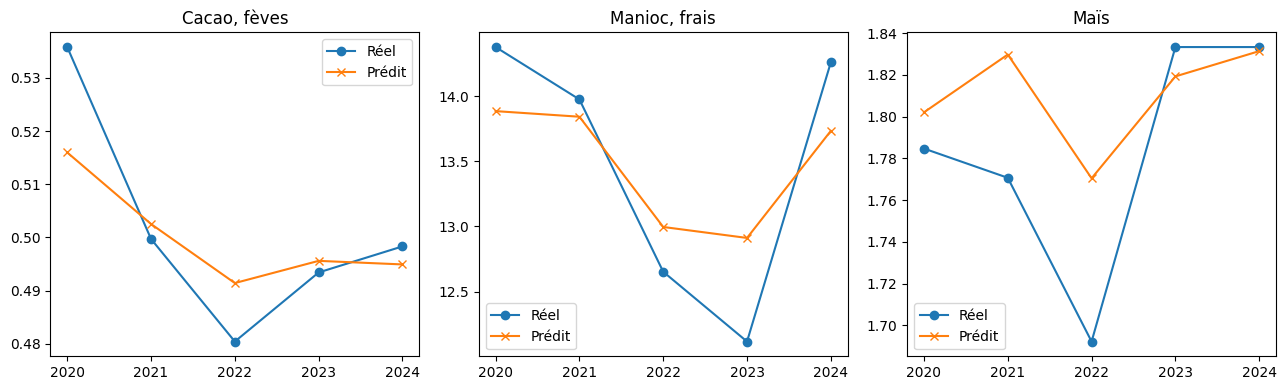

In [7]:
import sys
sys.path.insert(0, "..")
from src.common import NUM, CAT, TARGET, temporal_split

_, test = temporal_split(df, n_test_years=5)
test = test.copy()
test["pred"] = pipe.predict(test[NUM + CAT])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, crop in zip(axes, sorted(df["crop"].unique())):
    sub = test[test["crop"] == crop]
    ax.plot(sub["year"], sub[TARGET], marker="o", label="Réel")
    ax.plot(sub["year"], sub["pred"], marker="x", label="Prédit")
    ax.set_title(crop)
    ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/pred_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()